#### Importing Required Packages

In [4]:
# !pip install seaborn==0.11.2  # required version for visualization

In [3]:
# !pip install scikit-learn==0.23.2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
# !pip install umap-learn
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os.path
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.patches as mpatches
%matplotlib inline
# import umap.umap_ as umap
import matplotlib

In [2]:
# sns.__version__ # Checking if the right version is installed

In [3]:
# sklearn.__version__

# Overal Intrinsic

## Exploratory Data Analysis and Visualization
Feel free to explore the data further on your own.


In [2]:
# # Define file paths
# load_path = r'Z:\HH\Deep_Learning\Models'
# name = r'\model_metrics_UnseenData_1_16'

# # Importing the DataFrame from an Excel file
# df = pd.read_excel(os.path.join(load_path + name + '.xlsx'),  header=None)
# df.describe()

In [51]:
# import warnings
# warnings.filterwarnings("ignore")
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# import os

# # Load Excel file
# load_path = r'D:\UMICH\Deep_Learning'
# name = r'\Deep Learning_model_metrics_UnseenData_1_16'
# df = pd.read_excel(os.path.join(load_path + name + '.xlsx'), header=0)

# # Fill down missing Number_of_Slices values
# df['Number_of_Slices'] = df['Number_of_Slices'].ffill()
# df = df.dropna(subset=['Number_of_Slices'])
# df['Number_of_Slices'] = df['Number_of_Slices'].astype(int)

# # Prepare data
# df['Metric'] = df['Metrics']
# df = df.set_index(df.columns[0])
# melted = df.melt(id_vars=['Metric', 'Number_of_Slices'], var_name='Model', value_name='Score')

# # Define the metrics to plot
# metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC']

# # Set up subplots
# fig, axes = plt.subplots(2, 3, figsize=(18, 10),
#                         sharey=True,
#                         )
# axes = axes.flatten()
# palette = sns.color_palette("pastel")  # Softer colors
# # Plot each metric
# for idx, metric in enumerate(metrics):
#     ax = axes[idx]
#     metric_df = melted[melted['Metric'] == metric]
#     sns.lineplot(data=metric_df, x='Number_of_Slices', y='Score', hue='Model', 
#                 marker='o', linewidth=5.5, palette=palette,
#                 ax=ax)
#     # Adjust marker size
#     for line in ax.lines:
#         line.set_markersize(10)
#         # line.set_markerfacecolor('k')  # Fill color of the marker
#         line.set_markeredgecolor('k')  # Edge color of the marker

#     # Add horizontal dashed red line at y=0.5
#     ax.axhline(0.5, color='k', linestyle='--', linewidth=2)

    
#     ax.set_title(f'{metric} vs Number of Slices')
#     ax.set_xlabel('Number of Slices')
#     ax.set_ylabel(metric)
#     ax.grid(False)
#     ax.spines['top'].set_visible(False)
#     ax.spines['right'].set_visible(False)
#     ax.legend().set_title('Model')

# # Turn off the last empty subplot
# if len(metrics) < len(axes):
#     axes[-1].axis('off')

# plt.tight_layout()
# plt.show()



unmatched IDs: 0
       slices  animals
Group                 
1          29        7
2          30        7
3          28        9

unit = animal_layer: 46 rows from 23 animals

explained variance %: [57.4 21.2  8.9  4.5  3.5  2.7  1.6]
cumulative        %: [57.4 78.7 87.5 92.  95.5 98.2 99.9]

loadings:
            PC1   PC2   PC3
theta_db   0.37 -0.17 -0.49
beta_db    0.42 -0.17 -0.12
gammaS_db  0.45 -0.08  0.09
gammaF_db  0.45  0.00  0.13
gamma_db   0.34  0.06  0.73
HFO_db     0.39  0.15 -0.30
thata_GBO  0.04  0.68 -0.29
theta_HFO  0.10  0.67  0.15


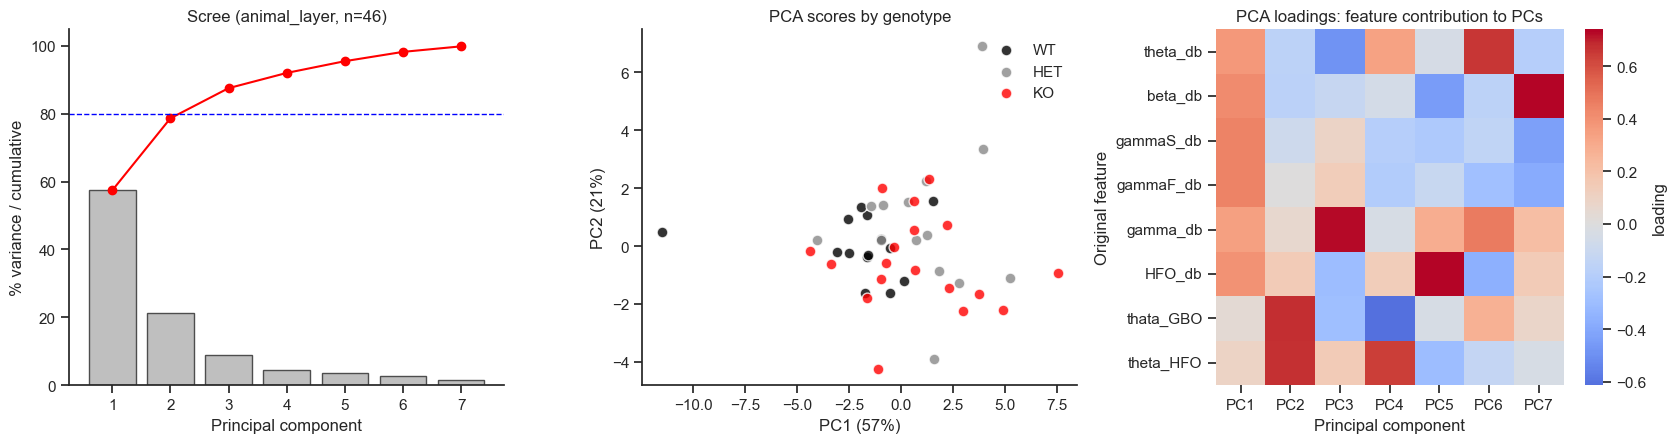

In [75]:
import os, re
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, QuantileTransformer
from sklearn.decomposition import PCA

# ------------------ Config ------------------ #
load_path = r'D:\UMICH\PaperSubmission\Deep_Learning\Data\Machine_Learning'
name = r'\Machine_Learning'
SAVE_DIR = r"D:\UMICH\PaperSubmission\Deep_Learning\Data\Machine_Learning\Figures"

AGG_LEVEL = 'animal_layer'   # 'animal_layer' | 'animal' | 'slice'
SCALER = 'quantile'          # 'standard' | 'quantile' | 'minmax'
LOG_POWER = True             # log10 the dB power columns (heavy right skew)

df = pd.read_excel(os.path.join(load_path + name + '.xlsx'), header=0)

group_col = 'Group'
power_vars = ['theta_db','beta_db','gammaS_db',
              'gammaF_db','gamma_db','HFO_db', ]     # continuous, NOT categorical
coupling_vars = ['thata_GBO','theta_HFO']          # continuous
features = power_vars + coupling_vars              # L2_3 / L5 are design, not features

# ------------------ Animal ID ------------------ #
# ID carries a stray leading byte, so use re.search (not match).
def animal_id(s):
    m = re.search(r'((?:20)?\d{1,2}-\d{2}-\d{2})', str(s))
    return m.group(1).replace('2024-','4-') if m else 'UNKNOWN'

df['Animal'] = df[group_col].astype(str) + '_' + df['ID'].map(animal_id)
df['Layer'] = np.where(df['L2_3'] == 1, 'L2_3', 'L5')
print("unmatched IDs:", (df.Animal.str.endswith('UNKNOWN')).sum())
print(df.groupby(group_col).agg(slices=('ID','size'), animals=('Animal','nunique')))

for c in features:
    df[c] = pd.to_numeric(df[c], errors='coerce')   # coerce, do NOT cast to int
df = df.dropna(subset=features).copy()

# ------------------ Collapse to unit of analysis ------------------ #
keys = {'animal_layer': ['Animal', group_col, 'Layer'],
        'animal':       ['Animal', group_col],
        'slice':        None}[AGG_LEVEL]
dat = df.groupby(keys, observed=True)[features].mean().reset_index() if keys else df.copy()
print(f"\nunit = {AGG_LEVEL}: {len(dat)} rows from {dat.Animal.nunique()} animals")

# ------------------ Scale ------------------ #
X = dat[features].copy()
if LOG_POWER:
    for c in power_vars:
        X[c] = np.log10(X[c].clip(lower=1e-6))

n = len(X)
scaler = {'standard': StandardScaler(),
          'minmax':   MinMaxScaler(),
          'quantile': QuantileTransformer(output_distribution='normal',
                                          n_quantiles=min(1000, n), random_state=0)}[SCALER]
X_scaled = scaler.fit_transform(X)

# ------------------ PCA ------------------ #
n_components = min(7, X.shape[1], n)
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)
for i in range(n_components):
    dat[f'PC{i+1}'] = X_pca[:, i]

var = pca.explained_variance_ratio_ * 100
print("\nexplained variance %:", var.round(1))
print("cumulative        %:", var.cumsum().round(1))
print("\nloadings:")
print(pd.DataFrame(pca.components_[:3].T, index=features,
                   columns=['PC1','PC2','PC3']).round(2))

# ------------------ Plots ------------------ #
sns.set(style='ticks')
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

ax[0].bar(range(1, n_components+1), var, color='0.75', edgecolor='0.3')
ax[0].plot(range(1, n_components+1), var.cumsum(), 'o-', color='red')
ax[0].axhline(80, ls='--', color='blue', lw=1)
ax[0].set_xlabel('Principal component'); ax[0].set_ylabel('% variance / cumulative')
ax[0].set_title(f'Scree ({AGG_LEVEL}, n={n})')

lbl = {1:'WT', 2:'HET', 3:'KO'}; col = {1:'#000000', 2:'#888888', 3:'#FF0000'}
for g, s in dat.groupby(group_col):
    ax[1].scatter(s.PC1, s.PC2, c=col.get(g,'k'), label=lbl.get(g,g),
                  s=60, alpha=.8, edgecolor='w')
ax[1].set_xlabel(f'PC1 ({var[0]:.0f}%)'); ax[1].set_ylabel(f'PC2 ({var[1]:.0f}%)')
ax[1].set_title('PCA scores by genotype'); ax[1].legend(frameon=False)

# ------------------ PC loadings (all components) ------------------ #
loadings = pd.DataFrame(pca.components_.T,
                        columns=[f'PC{i+1}' for i in range(n_components)],
                        index=features)

sns.heatmap(loadings, cmap='coolwarm', center=0, annot=False, fmt='.2f',
            ax=ax[2], cbar_kws={'label': 'loading'})
ax[2].set_title('PCA loadings: feature contribution to PCs')
ax[2].set_xlabel('Principal component')
ax[2].set_ylabel('Original feature')

for a in ax[:2]:
    sns.despine(ax=a); a.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'pca_animal_level.png'), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(SAVE_DIR, 'pca_animal_level.svg'), dpi=300, bbox_inches='tight')
plt.show()

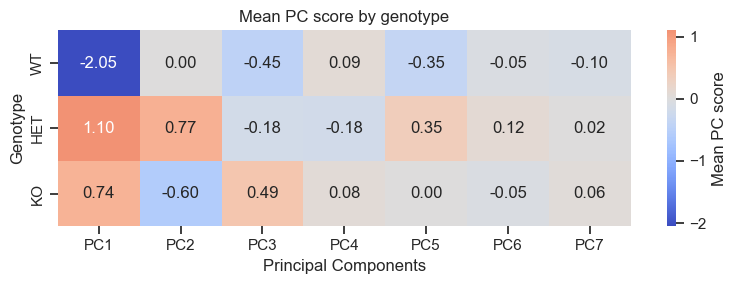

In [76]:
# Mean PC score: genotype (rows) × PCs (columns)
pcs = [f'PC{i+1}' for i in range(n_components)]
lbl = {1: 'WT', 2: 'HET', 3: 'KO'}

scores = dat.groupby('Group')[pcs].mean()
scores.index = [lbl.get(g, g) for g in scores.index]

plt.figure(figsize=(8, 3))
sns.heatmap(scores, cmap='coolwarm', center=0, annot=True, fmt='.2f',
            cbar_kws={'label': 'Mean PC score'})
plt.title('Mean PC score by genotype')
plt.xlabel('Principal Components')
plt.ylabel('Genotype')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'pca_animal_level_genotype.png'), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(SAVE_DIR, 'pca_animal_level_genotype.svg'), dpi=300, bbox_inches='tight')
plt.show()

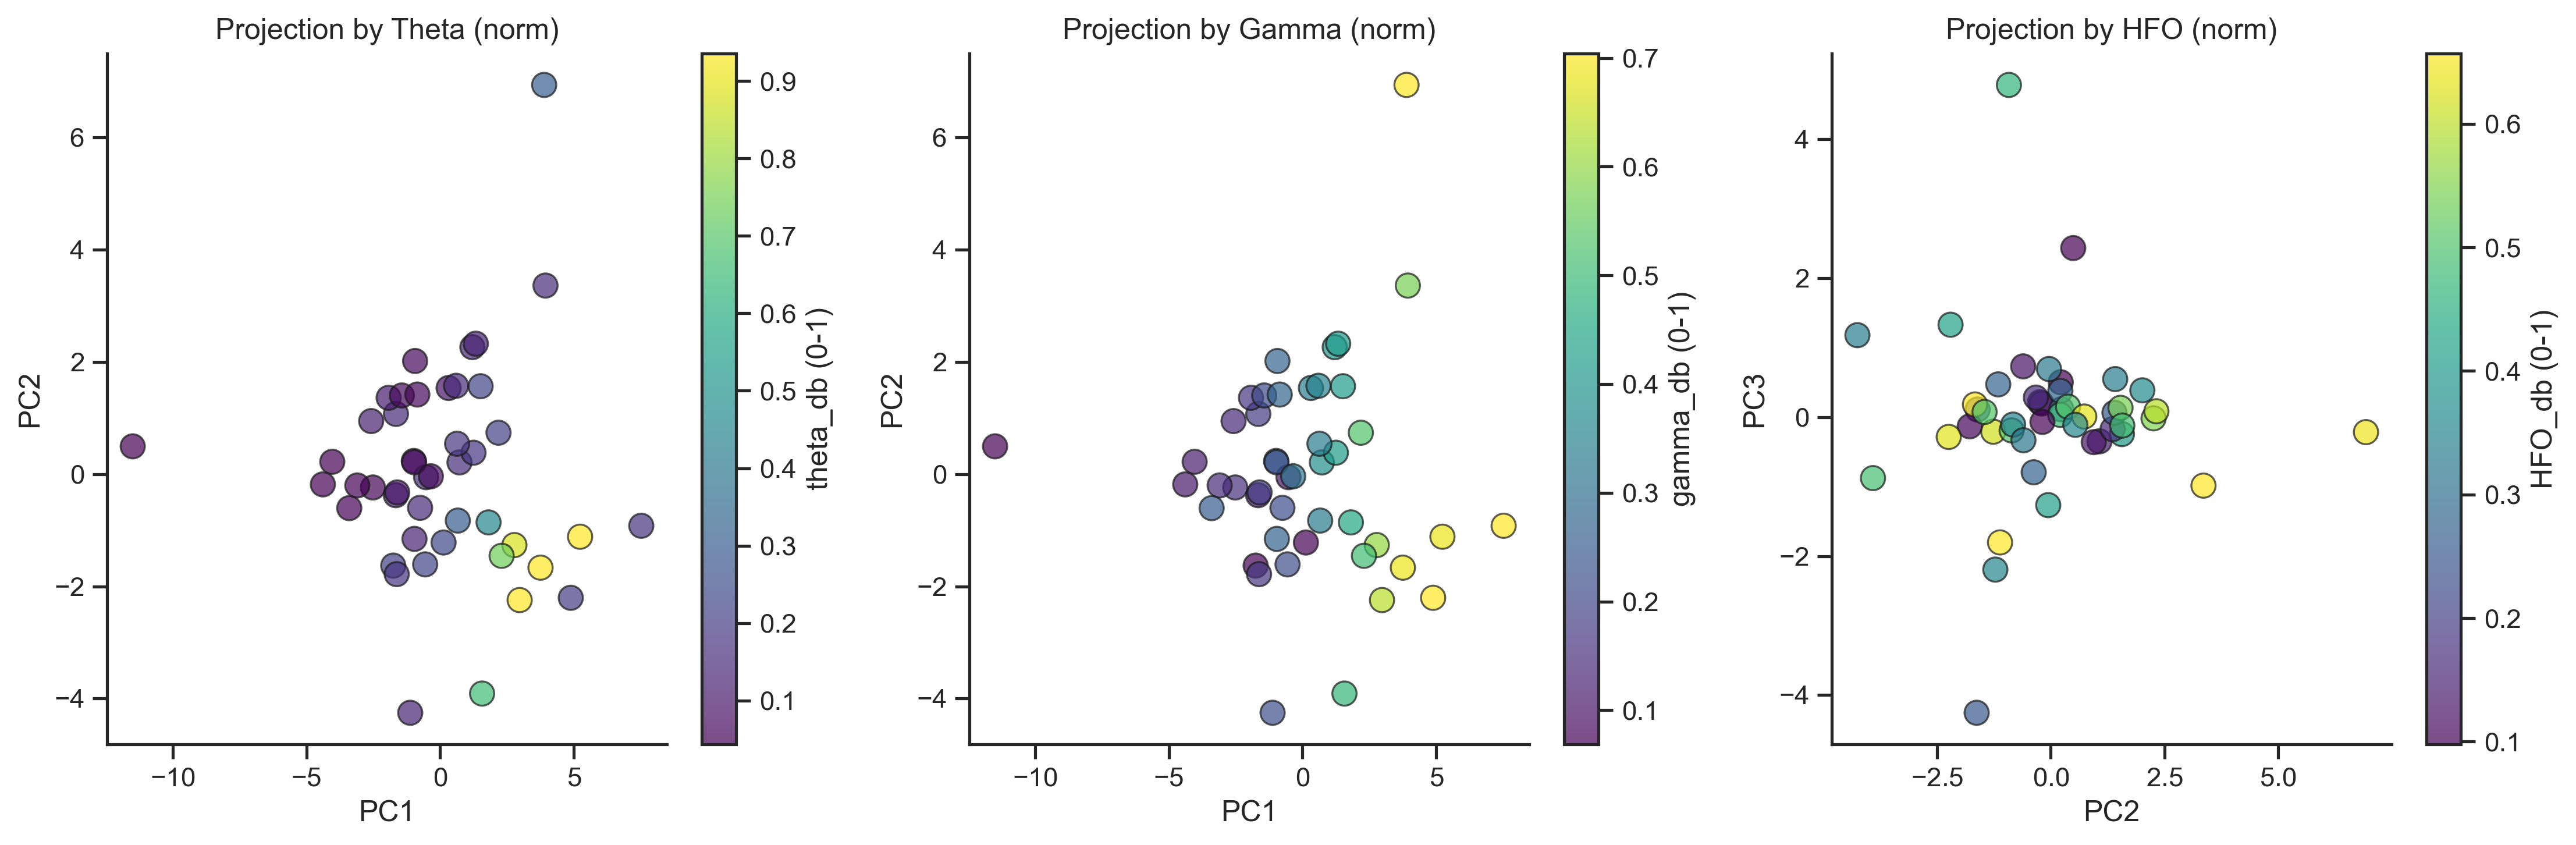

In [77]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import ScalarFormatter
from sklearn.preprocessing import MinMaxScaler

# normalize on dat -- the frame that holds the PCs
norm_vars = ['theta_db', 'gamma_db', 'HFO_db']
for c in norm_vars:
    dat[c + '_norm'] = MinMaxScaler().fit_transform(dat[[c]])

plot_settings = [
    ('PC1', 'PC2', 'theta_db_norm', 'viridis', 'Projection by Theta (norm)'),
    ('PC1', 'PC2', 'gamma_db_norm', 'viridis', 'Projection by Gamma (norm)'),
    ('PC2', 'PC3', 'HFO_db_norm',   'viridis', 'Projection by HFO (norm)'),
]

fig, axes = plt.subplots(1, len(plot_settings),
                         figsize=(5*len(plot_settings), 5), dpi=300)

for ax, (x, y, hue, cmap, title) in zip(np.atleast_1d(axes), plot_settings):
    sc = ax.scatter(dat[x], dat[y], c=dat[hue], cmap=cmap, s=100,edgecolor='k', linewidth=0.8, alpha=0.7,
                    vmin=dat[hue].quantile(0.05), vmax=dat[hue].quantile(0.95))
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label(hue.replace('_norm', ' (0-1)'))

    ax.set_title(title)
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.xaxis.set_major_formatter(ScalarFormatter(useMathText=True))
    ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=True))
    ax.ticklabel_format(axis='both', style='sci', scilimits=(-2, 2))

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'pca_Two_dimensional.png'), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(SAVE_DIR, 'pca_Two_dimensional.svg'), dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.preprocessing import QuantileTransformer
import pandas as pd
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# ------------------ Config ------------------ #
# feature order as displayed, TOP to BOTTOM
features = ['theta_db', 'beta_db', 'gammaS_db', 'gammaF_db',
            'gamma_db', 'HFO_db', 'thata_GBO', 'theta_HFO']

BETA_NORM = 'max'      # 'max' = beta / max|beta|  |  'z' = z-score  |  'none'

# ------------------ Data (animal level) ------------------ #
# dat is the animal-level frame built by the PCA cell, NOT the slice-level df
data = dat.reset_index(drop=True)
groups = sorted(data['Group'].unique())
lbl = {1: 'WT', 2: 'HET', 3: 'KO'}
print(f"n = {len(data)} rows from {data['Animal'].nunique()} animals")

# ------------------ Scale features ------------------ #
scaler = QuantileTransformer(output_distribution='normal',
                             n_quantiles=min(1000, len(data)), random_state=0)
X_scaled = pd.DataFrame(scaler.fit_transform(data[features]), columns=features)

# ------------------ Binary GLM per group vs rest ------------------ #
fig, axes = plt.subplots(1, len(groups), figsize=(4.5 * len(groups) + 1.5, len(features) * 0.45))

for ax, target_group in zip(axes, groups):
    y = (data['Group'] == target_group).astype(int)

    result = sm.GLM(y, sm.add_constant(X_scaled),
                    family=sm.families.Binomial()).fit()
    if not result.converged:
        print(f"WARNING: group {target_group} did not converge")

    # keep the given feature order; reverse because barh draws bottom-up
    order = features[::-1]
    coefs_ordered = result.params.reindex(order)
    pvals_ordered = result.pvalues.reindex(order)

    # ---- normalize beta ----
    if BETA_NORM == 'max':
        coefs_plot = coefs_ordered.values / np.abs(coefs_ordered.values).max()
    elif BETA_NORM == 'z':
        v = coefs_ordered.values
        coefs_plot = (v - v.mean()) / v.std()
    else:
        coefs_plot = coefs_ordered.values

    cmap = plt.cm.viridis_r
    norm = Normalize(vmin=-np.max(np.abs(coefs_plot)),
                     vmax= np.max(np.abs(coefs_plot)))

    # ---- plot ----
    ax.barh(y=order, width=pvals_ordered.values,
            color=cmap(norm(coefs_plot)), edgecolor='black')
    ax.axvline(0.05, linestyle='--', color='black', linewidth=1)
    ax.set_xlabel('P-value')
    ax.set_ylabel('Feature')
    ax.set_title(f'{lbl.get(target_group, target_group)} vs All Others')
    ax.grid(False)
    sns.despine(ax=ax, top=True, right=True)

    # significance stars
    for i, pval in enumerate(pvals_ordered.values):
        if pval < 0.07:
            ax.text(pval, i, ' *', va='center', ha='left', fontsize=12)

    # colorbar for normalized coefficients
    smappable = ScalarMappable(norm=norm, cmap=cmap)
    smappable.set_array([])
    cbar = fig.colorbar(smappable, ax=ax)
    cbar.set_label({'max': 'Beta / max|beta|',
                    'z':   'Beta (z)',
                    'none':'Coefficient'}[BETA_NORM])

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'GLM_group_vs_rest.png'), dpi=300, bbox_inches='tight')
plt.savefig(os.path.join(SAVE_DIR, 'GLM_group_vs_rest.svg'), dpi=300, bbox_inches='tight')
plt.show()

# Classification pipeline using machine learning on PC-transformed spectral features

unit = animal_layer: 46 rows, 23 animals
       rows  animals
Group               
1        14        7
2        14        7
3        18        9
🔍 SVC
🔍 DecisionTree
🔍 RandomForest
🔍 AdaBoost
🔍 XGBoost
🔍 LogisticRegression
🔍 KNN

chance level = 0.391
             Model  Accuracy  Accuracy_SEM  Precision  Precision_SEM  Recall  Recall_SEM  F1 Score  F1_SEM   AUC  AUC_SEM
               SVC     0.455         0.053      0.429          0.095   0.455       0.053     0.400   0.055 0.668    0.050
          AdaBoost     0.430         0.066      0.532          0.085   0.430       0.066     0.412   0.050 0.533    0.056
           XGBoost     0.430         0.066      0.476          0.092   0.430       0.066     0.400   0.062 0.544    0.068
LogisticRegression     0.430         0.053      0.434          0.086   0.430       0.053     0.377   0.054 0.692    0.087
      RandomForest     0.365         0.043      0.320          0.045   0.365       0.043     0.320   0.040 0.515    0.038
      DecisionTr

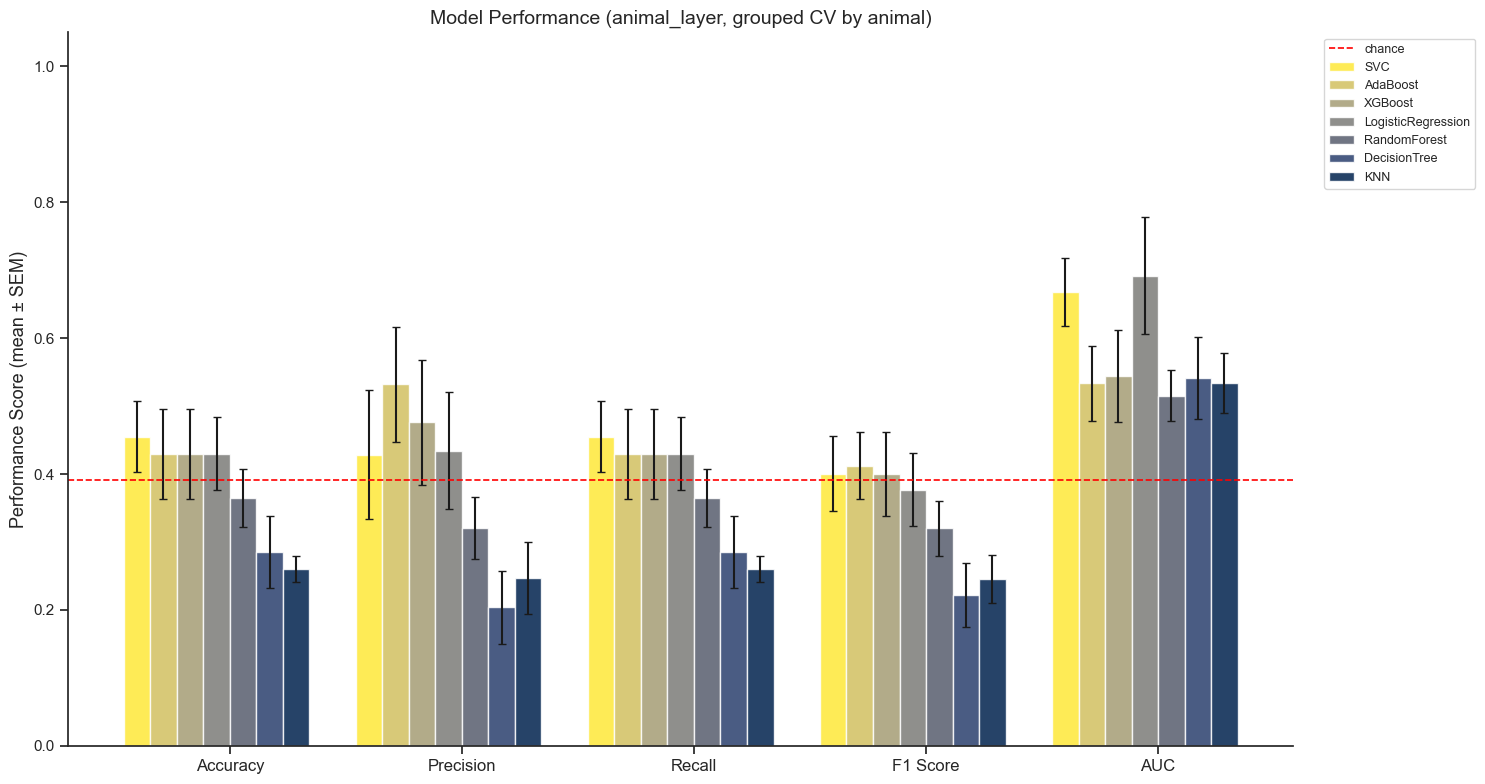

In [61]:
import os, re, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.cm as cm

from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, QuantileTransformer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

rand_n = 10
PCA_n = 7
AGG_LEVEL = 'animal_layer'    # 'animal_layer' | 'animal' | 'slice'

# ============================================================
# DATA -> ANIMAL LEVEL
# ============================================================
def animal_id(s):
    m = re.search(r'((?:20)?\d{1,2}-\d{2}-\d{2})', str(s))   # search: ID has a stray leading byte
    return m.group(1).replace('2024-','4-') if m else 'UNK'

df['Animal'] = df['Group'].astype(str) + '_' + df['ID'].map(animal_id)
df['Layer'] = np.where(df['L2_3'] == 1, 'L2_3', 'L5')

ALL = ['delta_db','theta_db','beta_db','gammaS_db','gammaF_db',
       'gamma_db','HFO_db','thata_GBO','theta_HFO']
exclude = ['delta_db','theta_db','beta_db','gammaS_db','gammaF_db',]
exclude = []
features = [v for v in ALL if v not in exclude]

for c in ALL:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.dropna(subset=features)

keys = {'animal_layer': ['Animal','Group','Layer'],
        'animal':       ['Animal','Group'],
        'slice':        None}[AGG_LEVEL]
dat = df.groupby(keys, observed=True)[features].mean().reset_index() if keys else df.copy()
print(f"unit = {AGG_LEVEL}: {len(dat)} rows, {dat.Animal.nunique()} animals")
print(dat.groupby('Group').agg(rows=('Animal','size'), animals=('Animal','nunique')))

X_raw  = dat[features].values           # NOT pre-scaled: scaling happens inside each fold
y      = LabelEncoder().fit_transform(dat['Group'].values)
groups = dat['Animal'].values           # <- keeps an animal in ONE fold only

# ============================================================
# MODELS / PARAMS
# ============================================================
models = {
    "SVC": SVC(probability=True),
    "DecisionTree": DecisionTreeClassifier(random_state=rand_n),
    "RandomForest": RandomForestClassifier(random_state=rand_n),
    "AdaBoost": AdaBoostClassifier(random_state=rand_n),
    "XGBoost": XGBClassifier(eval_metric='logloss'),
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier()
}
param_distributions = {
    "SVC": {'C': np.logspace(-2, 1, 20), 'kernel': ['linear','rbf']},
    "DecisionTree": {'max_depth': np.arange(2, 20)},
    "RandomForest": {'n_estimators': np.arange(50, 300), 'max_depth': np.arange(3, 20)},
    "AdaBoost": {'n_estimators': np.arange(50, 300), 'learning_rate': np.linspace(0.01, 1, 20)},
    "XGBoost": {'n_estimators': np.arange(50, 300), 'learning_rate': np.linspace(0.01, 0.3, 20)},
    "LogisticRegression": {'C': np.logspace(-2, 1, 20)},
    "KNN": {'n_neighbors': np.arange(3, 15)}
}

# ============================================================
# NESTED CV, GROUPED BY ANIMAL
# ============================================================
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=rand_n)
results = []

for name, model in models.items():
    print(f"🔍 {name}")
    fold_scores = []

    for train_idx, test_idx in outer_cv.split(X_raw, y, groups=groups):
        assert not set(groups[train_idx]) & set(groups[test_idx]), "animal leaked across folds"

        # scale INSIDE the fold, fit on train only
        scaler = QuantileTransformer(output_distribution='normal',
                                     n_quantiles=min(1000, len(train_idx)),
                                     random_state=rand_n)
        X_train = scaler.fit_transform(X_raw[train_idx])
        X_test  = scaler.transform(X_raw[test_idx])

        pca = PCA(n_components=min(PCA_n, X_train.shape[1]))
        X_train = pca.fit_transform(X_train)
        X_test  = pca.transform(X_test)

        # inner CV also grouped by animal
        search = RandomizedSearchCV(model, param_distributions[name], n_iter=40,
                                    cv=GroupKFold(n_splits=3), scoring='accuracy',
                                    random_state=rand_n, n_jobs=-1)
        search.fit(X_train, y[train_idx], groups=groups[train_idx])
        best_model = search.best_estimator_

        y_pred = best_model.predict(X_test)
        try:
            auc = roc_auc_score(y[test_idx], best_model.predict_proba(X_test),
                                multi_class='ovr', average='weighted')
        except Exception:
            auc = np.nan

        fold_scores.append([
            accuracy_score(y[test_idx], y_pred),
            precision_score(y[test_idx], y_pred, average='weighted', zero_division=0),
            recall_score(y[test_idx], y_pred, average='weighted', zero_division=0),
            f1_score(y[test_idx], y_pred, average='weighted', zero_division=0),
            auc])

    f = np.array(fold_scores); n = len(f)
    results.append({"Model": name,
        "Accuracy":  f[:,0].mean(), "Accuracy_SEM":  f[:,0].std(ddof=1)/np.sqrt(n),
        "Precision": f[:,1].mean(), "Precision_SEM": f[:,1].std(ddof=1)/np.sqrt(n),
        "Recall":    f[:,2].mean(), "Recall_SEM":    f[:,2].std(ddof=1)/np.sqrt(n),
        "F1 Score":  f[:,3].mean(), "F1_SEM":        f[:,3].std(ddof=1)/np.sqrt(n),
        "AUC":   np.nanmean(f[:,4]), "AUC_SEM":   np.nanstd(f[:,4], ddof=1)/np.sqrt(n)})

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
chance = max(np.bincount(y)) / len(y)
print(f"\nchance level = {chance:.3f}")
print(results_df.round(3).to_string(index=False))

# ============================================================
# PLOT
# ============================================================
colors = cm.cividis_r(np.linspace(0, 1, len(results_df)))
metrics = ["Accuracy","Precision","Recall","F1 Score","AUC"]
sem_names = {"Accuracy":"Accuracy_SEM","Precision":"Precision_SEM","Recall":"Recall_SEM",
             "F1 Score":"F1_SEM","AUC":"AUC_SEM"}
models_list = results_df["Model"].tolist()
x = np.arange(len(metrics)); width = 0.8 / len(models_list)

fig, ax = plt.subplots(figsize=(15, 8))
for i, m in enumerate(models_list):
    row = results_df[results_df.Model == m].iloc[0]
    ax.bar(x + i*width, [row[k] for k in metrics], width=width,
           yerr=[row[sem_names[k]] for k in metrics], capsize=3,
           label=m, alpha=.85, color=colors[i])

ax.axhline(chance, ls='--', color='red', lw=1.2, label='chance')
ax.set_xticks(x + width*len(models_list)/2); ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylabel("Performance Score (mean ± SEM)", fontsize=13)
ax.set_title(f"Model Performance ({AGG_LEVEL}, grouped CV by animal)", fontsize=14)
ax.set_ylim(0, 1.05)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()


os.makedirs(SAVE_DIR, exist_ok=True)
plt.savefig(os.path.join(SAVE_DIR, "model_performance_sem.svg"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(SAVE_DIR, "model_performance_sem.jpg"), dpi=300, bbox_inches="tight")
plt.show()

🔍 CM: SVC
🔍 CM: DecisionTree
🔍 CM: RandomForest
🔍 CM: AdaBoost
🔍 CM: XGBoost
🔍 CM: LogisticRegression
🔍 CM: KNN


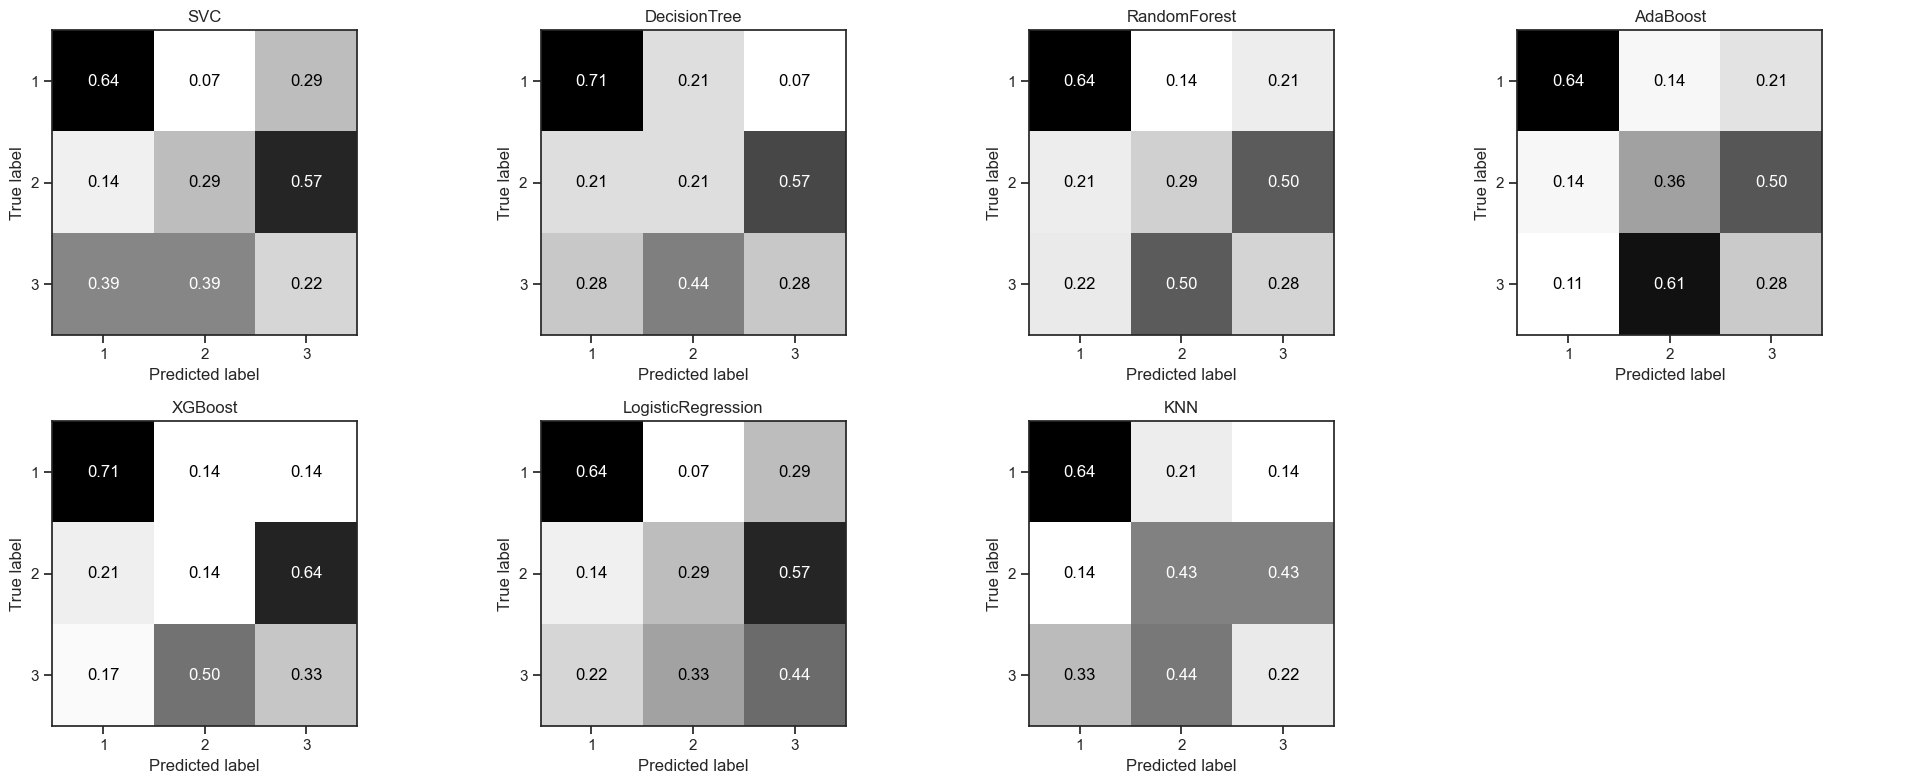

In [65]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import QuantileTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder().fit(dat['Group'].values)   # same encoding as y in the main pipeline



# ============================================================
# OUTER CV (same as your pipeline)
# ============================================================

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=rand_n)

n_models = len(models)
n_cols = 4
n_rows = (n_models + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))
axes = axes.flatten()

# ============================================================
# LOOP MODELS
# ============================================================

for i, (name, model) in enumerate(models.items()):

    y_true_all = []
    y_pred_all = []

    print(f"🔍 CM: {name}")

    for train_idx, test_idx in outer_cv.split(X_raw, y):

        # split
        X_train_raw, X_test_raw = X_raw[train_idx], X_raw[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # scaling
        scaler = QuantileTransformer(output_distribution='uniform')
        X_train_scaled = scaler.fit_transform(X_train_raw)
        X_test_scaled = scaler.transform(X_test_raw)

        # PCA
        pca = PCA(n_components=PCA_n)
        X_train = pca.fit_transform(X_train_scaled)
        X_test = pca.transform(X_test_scaled)

        # train best model (default params or you can plug best from search)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        y_true_all.extend(y_test)
        y_pred_all.extend(y_pred)

    # ========================================================
    # CONFUSION MATRIX (AGGREGATED)
    # ========================================================

    cm = confusion_matrix(y_true_all, y_pred_all, labels=[0, 1, 2],normalize='true')

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=le.classes_
    )

    disp.plot(ax=axes[i], cmap="Greys", colorbar=False, values_format=".2f")

    axes[i].set_title(name)

# ============================================================
# TURN OFF EMPTY PLOTS
# ============================================================

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

# ============================================================
# SAVE + SHOW
# ============================================================

fig.tight_layout()

plt.savefig(os.path.join(SAVE_DIR, "confusion_matrices_CV.svg"),dpi=300,bbox_inches="tight")
plt.savefig(os.path.join(SAVE_DIR, "confusion_matrices_CV.jpg"),dpi=300,bbox_inches="tight")

plt.show()

100 permutations x 7 models (23 animals, 46 rows)
  permutation 10/100
  permutation 20/100
  permutation 30/100
  permutation 40/100
  permutation 50/100
  permutation 60/100
  permutation 70/100
  permutation 80/100
  permutation 90/100
  permutation 100/100

chance (majority class) = 0.391
             Model  Observed  Null_mean  Null_SD  n_ge  p_perm  p_fdr
               SVC     0.455     0.2704   0.1025     2  0.0297 0.1040
          AdaBoost     0.430     0.3014   0.0807     4  0.0495 0.1040
           XGBoost     0.430     0.3039   0.0803     5  0.0594 0.1040
LogisticRegression     0.430     0.2635   0.0967     5  0.0594 0.1040
      RandomForest     0.365     0.2974   0.0882    23  0.2376 0.3327
      DecisionTree     0.285     0.3040   0.0828    59  0.5941 0.5941
               KNN     0.260     0.2805   0.0999    54  0.5446 0.5941

Selection-corrected: best observed = 0.455, best-of-null mean = 0.372, p = 0.1683


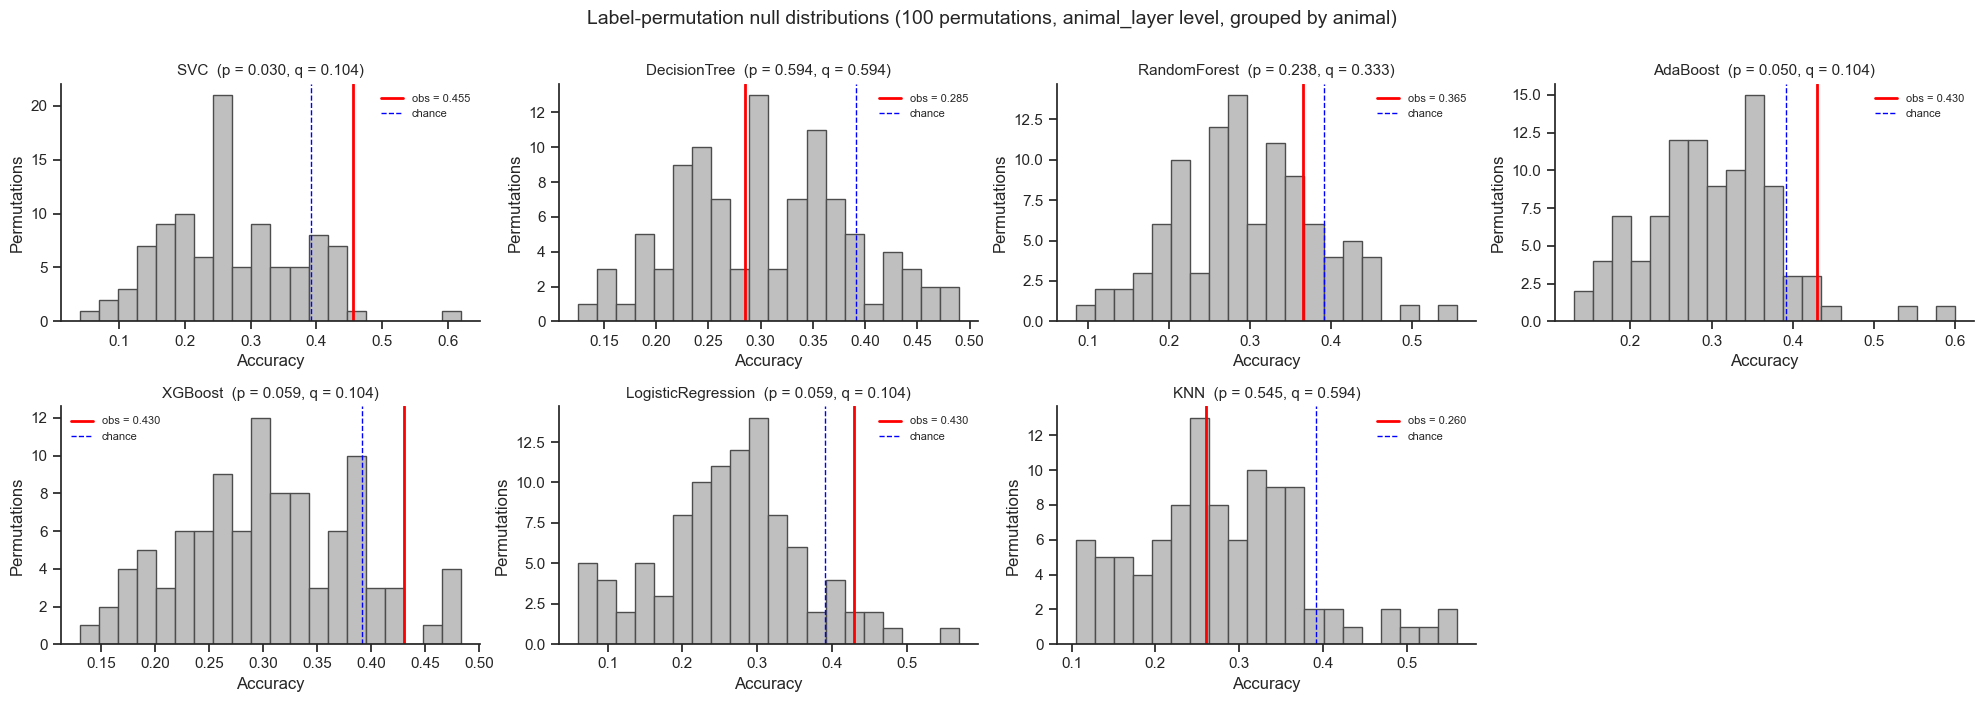

In [42]:
# ============================================================
# LABEL PERMUTATION TEST -- ALL MODELS, ANIMAL LEVEL
# ============================================================
N_PERMUTATIONS = 100
rng = np.random.RandomState(42)

# one label per animal, so shuffling preserves the group structure
animal_labels = pd.DataFrame({'Animal': groups, 'y': y}).drop_duplicates('Animal')
uniq_animals, uniq_y = animal_labels['Animal'].values, animal_labels['y'].values

# precompute the permuted label vectors so every model sees the SAME shuffles
perm_labels = []
for _ in range(N_PERMUTATIONS):
    shuffled = dict(zip(uniq_animals, rng.permutation(uniq_y)))
    perm_labels.append(np.array([shuffled[a] for a in groups]))

print(f"{N_PERMUTATIONS} permutations x {len(models)} models "
      f"({len(uniq_animals)} animals, {len(y)} rows)")


def cv_accuracy(model_name, labels):
    """mean outer-fold accuracy for one model and one label vector"""
    scores = []
    for tr, te in outer_cv.split(X_raw, labels, groups=groups):
        sc = QuantileTransformer(output_distribution='normal',
                                 n_quantiles=min(1000, len(tr)), random_state=rand_n)
        X_tr, X_te = sc.fit_transform(X_raw[tr]), sc.transform(X_raw[te])
        p = PCA(n_components=min(PCA_n, X_tr.shape[1]))
        X_tr, X_te = p.fit_transform(X_tr), p.transform(X_te)
        s = RandomizedSearchCV(models[model_name], param_distributions[model_name],
                               n_iter=20, cv=GroupKFold(n_splits=3), scoring="accuracy",
                               random_state=rand_n, n_jobs=-1)
        s.fit(X_tr, labels[tr], groups=groups[tr])
        scores.append(accuracy_score(labels[te], s.best_estimator_.predict(X_te)))
    return np.mean(scores)


# ---- run: rows = permutations, columns = models ----
null_mat = np.zeros((N_PERMUTATIONS, len(models)))
model_names = list(models.keys())

for p_i, y_perm in enumerate(perm_labels):
    if (p_i + 1) % 10 == 0:
        print(f"  permutation {p_i + 1}/{N_PERMUTATIONS}")
    for m_i, name in enumerate(model_names):
        null_mat[p_i, m_i] = cv_accuracy(name, y_perm)

null_df = pd.DataFrame(null_mat, columns=model_names)
null_df.to_csv(os.path.join(SAVE_DIR, "permutation_null.csv"), index=False)

# ============================================================
# P-VALUES
# ============================================================
chance = max(np.bincount(y)) / len(y)
rows = []
for name in model_names:
    obs = results_df.loc[results_df.Model == name, "Accuracy"].iloc[0]
    n_ge = int((null_df[name] >= obs).sum())
    rows.append(dict(Model=name, Observed=obs,
                     Null_mean=null_df[name].mean(),
                     Null_SD=null_df[name].std(ddof=1),
                     n_ge=n_ge,
                     p_perm=(n_ge + 1) / (N_PERMUTATIONS + 1)))

perm_df = pd.DataFrame(rows).sort_values("Observed", ascending=False)
perm_df["p_fdr"] = multipletests(perm_df.p_perm, method="fdr_bh")[1]

# ---- selection-corrected test: best model in each permutation ----
best_null = null_df.max(axis=1).values
best_obs = results_df["Accuracy"].max()
p_selection = ((best_null >= best_obs).sum() + 1) / (N_PERMUTATIONS + 1)

print(f"\nchance (majority class) = {chance:.3f}")
print(perm_df.round(4).to_string(index=False))
print(f"\nSelection-corrected: best observed = {best_obs:.3f}, "
      f"best-of-null mean = {best_null.mean():.3f}, p = {p_selection:.4f}")
results_df.to_csv(os.path.join(SAVE_DIR, "observed_results.csv"), index=False)
# ============================================================
# PLOT: null distribution per model
# ============================================================
n_cols = 4
n_rows = (len(model_names) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 3.5*n_rows))
axes = axes.flatten()

for i, name in enumerate(model_names):
    r = perm_df[perm_df.Model == name].iloc[0]
    axes[i].hist(null_df[name], bins=20, color="0.75", edgecolor="0.3")
    axes[i].axvline(r.Observed, color="red", lw=2, label=f"obs = {r.Observed:.3f}")
    axes[i].axvline(chance, color="blue", ls="--", lw=1, label="chance")
    axes[i].set_title(f"{name}  (p = {r.p_perm:.3f}, q = {r.p_fdr:.3f})", fontsize=11)
    axes[i].set_xlabel("Accuracy"); axes[i].set_ylabel("Permutations")
    axes[i].legend(frameon=False, fontsize=8)
    axes[i].spines[["top", "right"]].set_visible(False)

for j in range(len(model_names), len(axes)):
    axes[j].axis("off")

fig.suptitle(f"Label-permutation null distributions "
             f"({N_PERMUTATIONS} permutations, {AGG_LEVEL} level, grouped by animal)",
             y=1.00, fontsize=14)
fig.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "permutation_all_models.svg"),
            dpi=300, bbox_inches="tight")
plt.show()

             Model  Observed  Null_mean  Null_SD  n_ge  p_perm  p_fdr
               SVC     0.455     0.2704   0.1025     2  0.0297 0.1213
          AdaBoost     0.430     0.3014   0.0807     5  0.0594 0.1213
           XGBoost     0.430     0.3039   0.0803     6  0.0693 0.1213
LogisticRegression     0.430     0.2635   0.0967     5  0.0594 0.1213
      RandomForest     0.365     0.2974   0.0882    23  0.2376 0.3327
      DecisionTree     0.285     0.3040   0.0828    59  0.5941 0.5941
               KNN     0.260     0.2805   0.0999    54  0.5446 0.5941

Selection-corrected: best observed = 0.455, best-of-null mean = 0.372, p = 0.1683


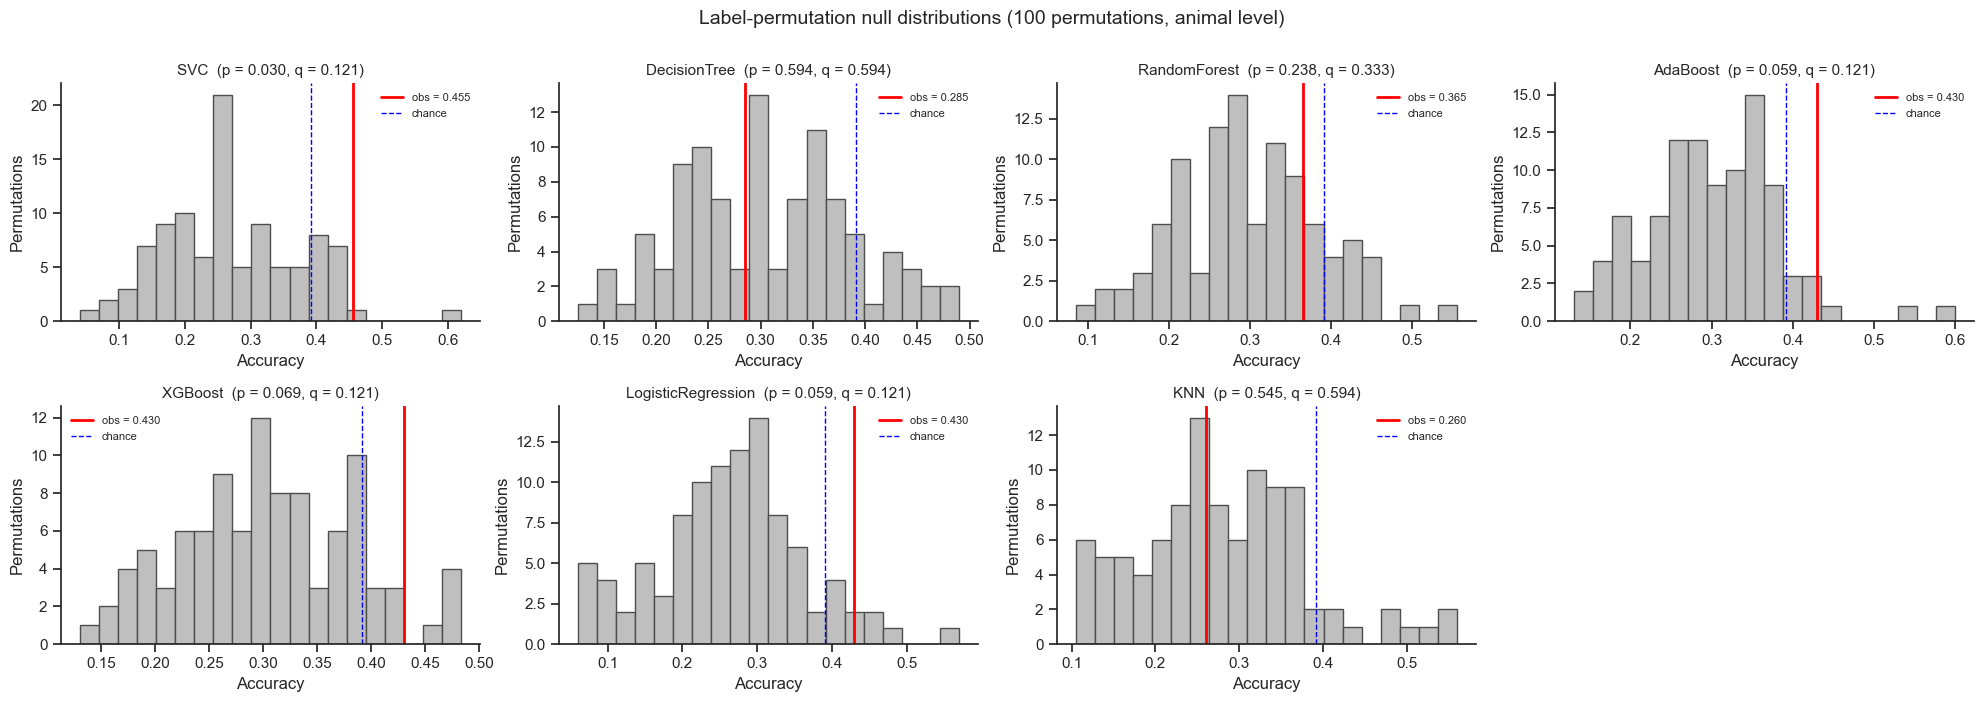

In [71]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

null_df = pd.read_csv(os.path.join(SAVE_DIR, "permutation_null.csv"))
results_df = pd.read_csv(os.path.join(SAVE_DIR, "observed_results.csv"))
N_PERMUTATIONS = len(null_df)
chance = 18 / 46                                   # majority class (KO rows / all rows)
model_names = list(null_df.columns)

# ---- p-values
rows = []
for name in model_names:
    obs = results_df.loc[results_df.Model == name, "Accuracy"].iloc[0]
    n_ge = int((null_df[name] >= obs).sum())
    rows.append(dict(Model=name, Observed=obs, Null_mean=null_df[name].mean(),
                     Null_SD=null_df[name].std(ddof=1), n_ge=n_ge,
                     p_perm=(n_ge + 1) / (N_PERMUTATIONS + 1)))
perm_df = pd.DataFrame(rows).sort_values("Observed", ascending=False)
perm_df["p_fdr"] = multipletests(perm_df.p_perm, method="fdr_bh")[1]
perm_df.to_csv(os.path.join(SAVE_DIR, "permutation_pvalues.csv"), index=False)

best_null = null_df.max(axis=1).values
best_obs = results_df["Accuracy"].max()
p_selection = ((best_null >= best_obs).sum() + 1) / (N_PERMUTATIONS + 1)
print(perm_df.round(4).to_string(index=False))
print(f"\nSelection-corrected: best observed = {best_obs:.3f}, "
      f"best-of-null mean = {best_null.mean():.3f}, p = {p_selection:.4f}")

# ---- plot
n_cols = 4
n_rows = (len(model_names) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
axes = axes.flatten()
for i, name in enumerate(model_names):
    r = perm_df[perm_df.Model == name].iloc[0]
    axes[i].hist(null_df[name], bins=20, color="0.75", edgecolor="0.3")
    axes[i].axvline(r.Observed, color="red", lw=2, label=f"obs = {r.Observed:.3f}")
    axes[i].axvline(chance, color="blue", ls="--", lw=1, label="chance")
    axes[i].set_title(f"{name}  (p = {r.p_perm:.3f}, q = {r.p_fdr:.3f})", fontsize=11)
    axes[i].set_xlabel("Accuracy"); axes[i].set_ylabel("Permutations")
    axes[i].legend(frameon=False, fontsize=8)
    axes[i].spines[["top", "right"]].set_visible(False)
for j in range(len(model_names), len(axes)):
    axes[j].axis("off")
fig.suptitle(f"Label-permutation null distributions ({N_PERMUTATIONS} permutations, animal level)",
             y=1.00, fontsize=14)
fig.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "permutation_all_models.svg"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(SAVE_DIR, "permutation_all_models.jpg"), dpi=300, bbox_inches="tight")
plt.show()